# Solar filament instance segmentation: full pipeline

Kaggle *Solar Filament Segmentation Challenge 2026* (MAGFiLO, GONG H-alpha, 2048 x 2048 px).
This notebook reproduces the submitted predictions from the raw test images and the weights stored in
this repository (`weights/unet_r34_1536_all.pt`, `weights/tree_scorer_1536.pkl` and the five stage-2 refiners
`weights/stage2_unet_f{0..4}.pt`); no training is needed. Training, tuning and the
validation study are described at the end and can be re-run with the commands given there.

**Pipeline in one line:** downsample to 1536 px -> U-Net (ResNet-34 encoder, 1 input channel), averaged
over 4 flips (mean and per-pixel spread of the views) -> maps upsampled to 2048 px -> candidates at 12
thresholds (0.25-0.80; closing 31 px used only to group nearby fragments; 8-connected components of at
least 100 px), which nest into a tree -> a gradient-boosted hurdle model scores each node's expected PQ
contribution, P(match) x E[IoU | match], from 32 shape, probability, contrast, position, tree-context and
view-spread features -> the disjoint set of nodes maximising the sum of (score - 0.26), solved exactly on the
tree -> stage 2: each selected filament redrawn at native resolution in a crop turned along its own axis
(384 x 128 px; inputs image, stage-1 probability, the filament and its neighbours) by five refiner U-Nets,
averaged, thresholded at 0.40 and pasted back disjoint -> one compressed COCO RLE per filament.

Every design choice, with the experiments behind it (including the failed ones), is in `docs/DESIGN.md`.

## 1. Setup

In [1]:
import json, os, time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from pycocotools import mask as mask_util

from filseg.cache import downsample
from filseg.data import ROOT, SIZE, TEST_IMAGES, read_image
from filseg.geometry import fit_disk
from filseg.postprocess import upsample
from filseg.predict import write_csv
from filseg.stage2 import load_refiners, refine
from filseg.train import build_model, predict_with_spread
from filseg.tree import load_tree_scorer

# FILSEG_DEVICE overrides the automatic choice, e.g. FILSEG_DEVICE=cpu
DEVICE = os.environ.get("FILSEG_DEVICE") or ("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
WEIGHTS = ROOT / "weights" / "unet_r34_1536_all.pt"
TREE = load_tree_scorer(ROOT / "weights" / "tree_scorer_1536.pkl")
REFINERS = [ROOT / "weights" / f"stage2_unet_f{k}.pt" for k in range(5)]
OUTPUT = ROOT / "submissions" / "notebook_submission.csv"
RES = 1536  # network input resolution
print("device:", DEVICE, "| test images:", TEST_IMAGES.relative_to(ROOT))

device: mps | test images: data/raw/MAGFiLO_1.0_Kaggle_2026/test/test_images


## 2. Data

Test images are read from `data/raw/MAGFiLO_1.0_Kaggle_2026/test/test_images` (the competition's
download, unzipped into `data/raw/`). Only these H-alpha images are used at inference.

180 test images; first: 20110120105534Ch.jpeg


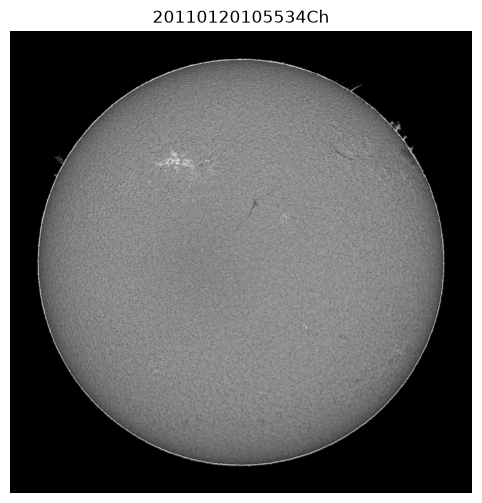

In [2]:
test_paths = sorted(TEST_IMAGES.glob("*.jpeg"))
print(len(test_paths), "test images; first:", test_paths[0].name)
example = read_image(test_paths[0])
plt.figure(figsize=(6, 6)); plt.imshow(example, cmap="gray"); plt.axis("off"); plt.title(test_paths[0].stem); plt.show()

## 3. Model

`segmentation_models_pytorch` U-Net with an ImageNet-initialised ResNet-34 encoder adapted to one
input channel, trained on all 707 training images at 1536 px for 40 epochs (BCE + soft Dice on the consensus
target: the fraction of annotators marking each pixel). The tree scorer (scikit-learn
HistGradientBoostingClassifier and Regressor, a hurdle model) was fitted on the out-of-fold tree nodes of
five fold models. The stage-2 refiners are U-Nets (ResNet-34 encoder, 4 input channels), one per fold,
each trained for 30 epochs on the other folds' crops with the mean of the matching annotators' masks as the
target, stored in float16. All are loaded here; nothing is trained.

In [3]:
model = build_model("resnet34", pretrained=False).to(DEVICE)
model.load_state_dict(torch.load(WEIGHTS, map_location=DEVICE))
model.eval()
refiners = load_refiners(REFINERS, DEVICE)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f} M parameters; {len(refiners)} refiners")

24.4 M parameters; 5 refiners


## 4. One image, step by step

Preprocessing is an area downsample to 1536 px and a fixed normalisation (inside `predict`). The
probability is the average over four flipped views, and their per-pixel standard deviation marks where
the model is unsure. Candidates are the connected components of the map at twelve thresholds; a component
at a higher threshold lies inside one at the next lower threshold, so they form a tree, and the selected
set (an antichain of that tree) is disjoint by construction. The solar disk is fitted with a Hough circle
on the limb and gives the position features. Stage 2 then redraws each selected filament from its own crop;
a filament mostly covered by its neighbours' redrawn masks is absorbed, and overlaps go to the instance with
the higher refined probability, so the masks stay disjoint.

stage 1: 2 filaments, stage 2: 2; disk centre (1026, 1030), radius 898 px


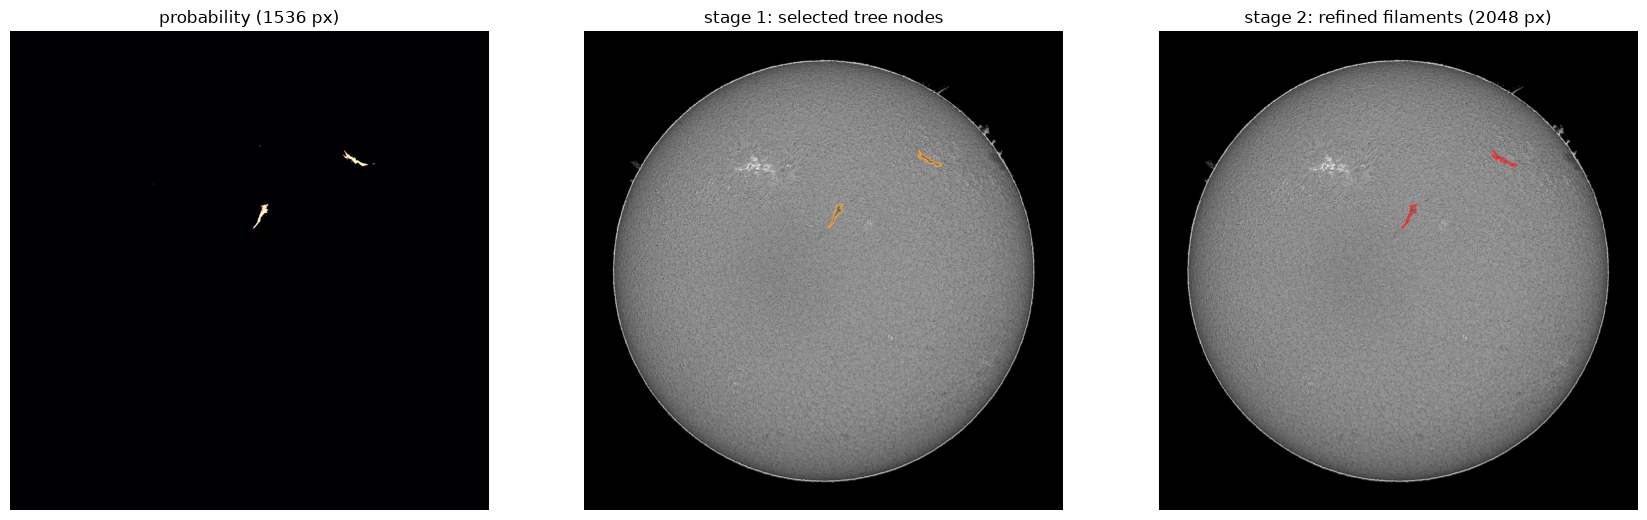

In [4]:
small = downsample(example, RES)
mean, spread = predict_with_spread(model, small[None], DEVICE)
prob = mean[0].astype(np.float32)
disk = fit_disk(small)
full = upsample(prob)
seeds, score = TREE.select_scored(full, example, disk, upsample(spread[0].astype(np.float32)))
rles = refine(refiners, example, full, seeds, score, DEVICE)
print(f"stage 1: {len(seeds)} filaments, stage 2: {len(rles)}; "
      f"disk centre ({disk.cx:.0f}, {disk.cy:.0f}), radius {disk.r:.0f} px")

def outline(masks, colour):
    overlay = cv2.cvtColor(example, cv2.COLOR_GRAY2RGB)
    for rle in masks:
        contours, _ = cv2.findContours(mask_util.decode(rle), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(overlay, contours, -1, colour, 3)
    return overlay

fig, ax = plt.subplots(1, 3, figsize=(21, 7))
ax[0].imshow(prob, cmap="magma", vmin=0, vmax=1); ax[0].set_title("probability (1536 px)")
ax[1].imshow(outline(seeds, (255, 160, 40))); ax[1].set_title("stage 1: selected tree nodes")
ax[2].imshow(outline(rles, (255, 40, 40))); ax[2].set_title("stage 2: refined filaments (2048 px)")
for a in ax: a.axis("off")
plt.show()

## 5. All test images -> submission CSV

In [5]:
started = time.time()
rows = []
for path in test_paths:
    image = read_image(path)
    small = downsample(image, RES)
    mean, spread = predict_with_spread(model, small[None], DEVICE)
    full = upsample(mean[0].astype(np.float32))
    seeds, score = TREE.select_scored(full, image, fit_disk(small), upsample(spread[0].astype(np.float32)))
    kept = refine(refiners, image, full, seeds, score, DEVICE)
    for n, rle in enumerate(kept, start=1):
        rows.append((f"{path.stem}_{n}", rle["counts"].decode()))
elapsed = time.time() - started
OUTPUT.parent.mkdir(exist_ok=True)
write_csv(rows, OUTPUT, [p.stem for p in test_paths])  # checks unique ids, known images, non-empty masks
n_images = len({r[0].rsplit('_', 1)[0] for r in rows})
print(f"{len(rows)} filaments on {n_images} of {len(test_paths)} images; "
      f"{elapsed / len(test_paths):.2f} s per image on {DEVICE}; written to {OUTPUT.relative_to(ROOT)}")

1066 filaments on 177 of 180 images; 11.42 s per image on mps; written to submissions/notebook_submission.csv


## 6. Validation study (pre-computed)

The figures below are the organisers' three evaluation plots computed on out-of-fold predictions:
five fold models (5-fold `GroupKFold` by calendar month, 707 images, 1,154 annotator-image entries),
each image scored by a model that never saw it, and a tree scorer trained on the other four folds'
nodes. Numbers are printed from `docs/figures/ooftree_stats.json`; the plots are reproduced by
`python -m filseg.report --tree runs/oof_tree12s_1536_v4.pkl --tau 0.26 --name ooftree` (section 7). For
reference, one annotator scored against another on the same images gives PQ 0.340, the single-threshold
scorer 0.422 and the earlier 1024 px pipeline with a fixed rule 0.409. These plots are of stage 1 (OOF PQ
0.4267). Stage 2, evaluated out of fold the same way (each fold's crops redrawn by the refiner that did not
see them), gives 0.4330, a paired gain of +0.0063 (bootstrap 95% interval 0.0033 to 0.0093;
`runs/stage2/unet_eval.json`, `scripts/experiments/stage2_oof.py`).

PQ=0.4267 SQ=0.6749 TP=4872 FP=2341 FN=3327 | mean IoU 0.5752 | mean Dice 0.7083


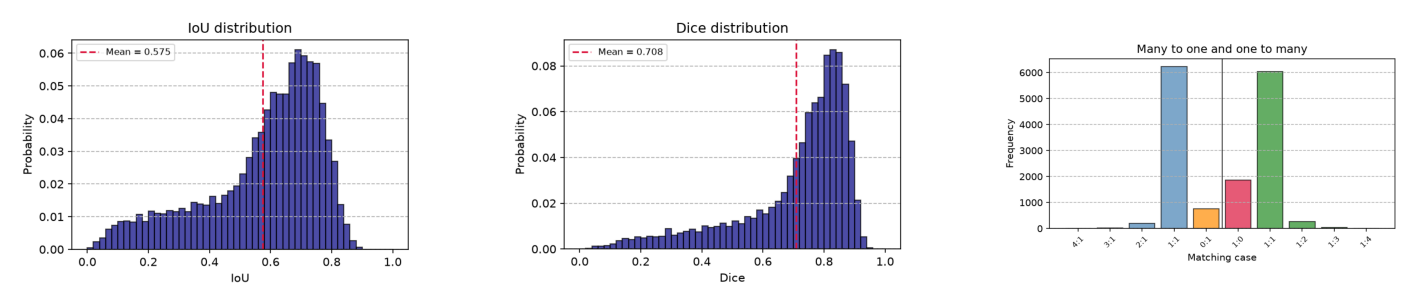

In [6]:
stats = json.loads((ROOT / "docs" / "figures" / "ooftree_stats.json").read_text())
print(stats["summary"], "| mean IoU", stats["mean_iou"], "| mean Dice", stats["mean_dice"])
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, name in zip(ax, ["iou", "dice", "m2n"]):
    a.imshow(plt.imread(ROOT / "docs" / "figures" / f"ooftree_{name}.png")); a.axis("off")
plt.show()

## 7. Training and tuning (reference; not run here)

Run from the repository root with the project's environment (`pip install -r requirements.txt`), with
`FILSEG_CACHE=data/cache1536` and `PYTHONPATH=.` set. One 40-epoch fold takes about 40 min on an A100
(we used Hugging Face Jobs, `scripts/hf/`) or about 3 h on an Apple M3 Max.
Set `RUN_TRAINING = True` below to run the final-model steps from the notebook.

| Step | Command |
|---|---|
| Cache images and consensus targets at 1536 px | `python -m filseg.cache --res 1536` |
| Train the five fold models | `python -m filseg.train --fold K --name unet_r34_1536 --epochs 40` for K = 0..4 |
| Out-of-fold probabilities with 4 flips | `python scripts/experiments/oof_probs_views.py --views 4 --name unet_r34_1536` |
| Out-of-fold spread of the 4 views | `python scripts/experiments/oof_view_spread.py --name unet_r34_1536` |
| Tree nodes and their features | `python scripts/experiments/component_tree.py build --spread --levels 0.25,0.3,0.35,0.4,0.45,0.5,0.55,0.6,0.65,0.7,0.75,0.8 --out runs/oof_tree12s_1536_v4.pkl` |
| Cross-validated scorers, choice of tau | `python scripts/experiments/component_tree.py eval --out runs/oof_tree12s_1536_v4.pkl --context --modes hurdle` |
| Final tree scorer on all nodes | `python -m filseg.tree --nodes runs/oof_tree12s_1536_v4.pkl --out weights/tree_scorer_1536.pkl --tau 0.26` |
| Evaluation plots | `python -m filseg.report --tree runs/oof_tree12s_1536_v4.pkl --tau 0.26 --name ooftree` |
| Final model on all 707 images | `python -m filseg.train --fold -1 --name unet_r34_1536 --epochs 40` |
| Stage-2 crops from the out-of-fold selections | `python scripts/experiments/stage2_oof.py crops --workers 4` |
| Stage-2 refiners, one per fold, and their out-of-fold crops | `python scripts/experiments/stage2_oof.py train --tag unet --epochs 30` |
| Stage-2 out-of-fold PQ against stage 1 | `python scripts/experiments/stage2_oof.py eval --tag unet --workers 4` |
| Refiners to float16 in `weights/` | `python scripts/experiments/stage2_oof.py export --tag unet` |
| Submission from the command line | `python -m filseg.predict --weights weights/unet_r34_1536_all.pt --views 4 --tree-scorer weights/tree_scorer_1536.pkl --refiner weights/stage2_unet_f0.pt weights/stage2_unet_f1.pt weights/stage2_unet_f2.pt weights/stage2_unet_f3.pt weights/stage2_unet_f4.pt` |

In [7]:
RUN_TRAINING = False
if RUN_TRAINING:
    import subprocess, sys
    env = {**os.environ, "FILSEG_CACHE": str(ROOT / "data" / "cache1536"), "PYTHONPATH": str(ROOT)}
    for args in (["filseg.cache", "--res", "1536"],
                 ["filseg.train", "--fold", "-1", "--name", "unet_r34_1536", "--epochs", "40"]):
        subprocess.run([sys.executable, "-m", *args], cwd=ROOT, env=env, check=True)